# 노면 균열 이미지 분할 (Semantic Segmentation)

## 📌 학습 목표
1. **객체 검출(Object Detection, Bounding Box)과 분할(Segmentation, Pixel-level Mask)의 근본적인 차이**와 현업 적용 기준을 이해합니다.
2. 가늘고 긴 비정형 객체(노면 균열 등)에서 왜 Bounding Box가 비효율적인지 정량적/시각적으로 확인합니다.
3. 이미지 분할의 대표 아키텍처인 **U-Net의 구조(Encoder, Bottleneck, Decoder, Skip Connection)**를 PyTorch로 직접 구현하고 텐서 흐름을 파악합니다.
4. 클래스 불균형(배경 98% vs 균열 2%) 문제를 해결하기 위한 **BCE + Dice 결합 손실 함수(Loss Function)**와 평가지표(**IoU, Dice Score**)를 구현합니다.

---
### ⚙️ 실습 전 환경 설정
- 상단 메뉴에서 **[런타임] → [런타임 유형 변경] → 하드웨어 가속기: GPU (T4)**를 반드시 선택해 주세요.
- 실습 데이터셋(`zip` 파일)은 Google Colab의 임시 저장소(`/content`)에 다운로드됩니다. 세션이 종료되면 `/content` 내부 파일은 초기화되므로 원본 압축 파일은 구글 드라이브에 보관합니다.

## 1. 데이터셋 경로 및 다운로드 주소 설정

- 구글 드라이브에 업로드된 실습용 `zip` 파일의 공유 권한을 **`링크가 있는 모든 사용자`**로 설정한 뒤, 공유 링크(또는 파일 ID)를 설정합니다.
- **참고**: 구글 드라이브 파일 크기가 100MB를 초과할 경우 일반 `wget` 명령어는 바이러스 검사 경고 페이지(HTML)만 다운로드하게 됩니다. 따라서 구글 드라이브 링크는 전용 다운로더인 `gdown`을 사용하고, 일반 웹 직링크(Direct URL)인 경우에만 `wget`을 사용하도록 분기 처리합니다.

In [ ]:
# 실습 데이터셋 구글 드라이브 파일 ID 및 공유 링크 구성
DRIVE_FILE_ID = "1ooQt7A3VxUBlnfy0VNLr-4u74c42w620"
DRIVE_HOST = "/".join(["https:", "", "drive." + "google." + "com", "file", "d"])
ZIP_URL = f"{DRIVE_HOST}/{DRIVE_FILE_ID}/view?usp=sharing"

# 작업 디렉토리 및 압축 파일 저장 경로 설정
TASK = "segmentation"
ZIP_PATH = "/content/03_segmentation.zip"  # 다운로드 받을 zip 파일의 로컬 경로
DST = f"/content/{TASK}"                    # 압축 해제 후 데이터가 위치할 폴더 경로

## 2. 필수 패키지 설치
구글 드라이브 대용량 파일 다운로드를 지원하는 `gdown` 패키지를 설치합니다. (`-q` 옵션은 출력 로그를 최소화합니다.)

In [ ]:
!pip install -q gdown

## 3. 데이터셋 다운로드 및 압축 해제

지정한 `ZIP_URL`로부터 압축 파일을 다운로드하고 `/content/segmentation` 경로에 압축을 해제합니다.
- 이미 정상적으로 다운로드된 파일(10KB 이상)이 존재하면 재다운로드를 건너뛰어 실습 시간을 절약합니다.

In [ ]:
from pathlib import Path
import os


def fetch_zip(url: str, dest: str):
    """
    지정된 URL(구글 드라이브 또는 일반 웹 링크)에서 zip 파일을 다운로드하는 함수입니다.

    Args:
        url (str): 다운로드할 파일의 URL 주소
        dest (str): 저장할 로컬 파일 경로
    """
    url = (url or "").strip()
    if not url or "여기에" in url:
        raise SystemExit(
            "[오류] 위 셀의 ZIP_URL 변수에 구글 드라이브 공유 링크(또는 직접 다운로드 주소)를 입력해 주세요."
        )

    # URL이 구글 드라이브 링크인지 판별
    is_drive = ("drive." + "google") in url or ("docs." + "google") in url

    dest = Path(dest)
    # 파일이 이미 존재하고 크기가 10,000 bytes(약 10KB)보다 크면 정상 파일로 간주하고 스킵
    if dest.exists() and dest.stat().st_size > 10_000:
        print(f"[안내] 이미 다운로드된 파일이 존재합니다: {dest} ({dest.stat().st_size:,} bytes)")
        return

    # 상위 폴더가 없으면 생성
    dest.parent.mkdir(parents=True, exist_ok=True)

    # 셸 명령어(!gdown, !wget)에서 참조할 수 있도록 환경 변수에 등록
    os.environ["ZIP_URL"] = url
    os.environ["ZIP_PATH"] = str(dest)

    if is_drive:
        # --fuzzy 옵션을 사용하면 일반 보기 링크에서도 파일 ID를 자동 추출해 다운로드함
        !gdown --fuzzy "$ZIP_URL" -O "$ZIP_PATH"
    else:
        # 일반 웹 URL인 경우 wget으로 이어받기(-c) 수행
        !wget -c -O "$ZIP_PATH" "$ZIP_URL"

    print(f"[완료] 다운로드 성공: {dest} ({dest.stat().st_size:,} bytes)")


# 압축 파일 다운로드 실행
fetch_zip(ZIP_URL, ZIP_PATH)

Downloading...
From (original): https://drive.google.com/uc?id=1ooQt7A3VxUBlnfy0VNLr-4u74c42w620
From (redirected): https://drive.google.com/uc?id=1ooQt7A3VxUBlnfy0VNLr-4u74c42w620&confirm=t&uuid=d2a488d3-56e2-4ea3-b5eb-5425df62ee77
To: /content/03_segmentation.zip
100% 104M/104M [00:03<00:00, 33.9MB/s] 
[완료] 다운로드 성공: /content/03_segmentation.zip (103,906,082 bytes)


In [ ]:
# 기존 압축 해제 폴더가 남아있을 경우 충돌 방지를 위해 초기화(삭제)
!rm -rf {DST}

In [ ]:
# 다운로드한 zip 파일을 /content 경로에 조용히(-q) 덮어쓰기(-o) 모드로 압축 해제
!unzip -q -o {ZIP_PATH} -d /content

In [ ]:
from pathlib import Path
import torch
from IPython.display import display
from PIL import Image

# 데이터셋 루트 경로 확인
ROOT = Path(DST)
if not ROOT.exists():
    raise SystemExit(f"[오류] {ROOT} 폴더가 존재하지 않습니다. zip 파일 내부에 '{TASK}' 폴더 구조가 맞는지 확인하세요.")

# 연산 장치(GPU / CPU) 설정 및 상태 출력
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("📂 데이터 루트 경로 (ROOT) :", ROOT)
print("🔥 PyTorch 버전           :", torch.__version__)
print("💻 사용 연산 장치 (DEVICE) :", DEVICE)
if DEVICE.type == "cuda":
    print("🚀 할당된 GPU 모델명      :", torch.cuda.get_device_name(0))
else:
    print("⚠️ 경고: 현재 CPU 모드입니다. 빠른 학습을 위해 GPU 런타임으로 변경하는 것을 권장합니다.")


def show_img(img: Image.Image, width: int = 900):
    """
    Jupyter/Colab 셀 출력창에 PIL 이미지를 보기 좋게 출력하는 헬퍼 함수입니다.
    이미지 가로 크기가 지정한 width보다 클 경우 비율을 유지하며 축소합니다.
    """
    img = img.convert("RGB")
    w, h = img.size
    if w > width:
        # 가로 폭(width)에 맞춰 세로 비율을 유지하여 리사이징 (Bilinear 보간법 사용)
        new_h = int(h * width / w)
        img = img.resize((width, new_h), Image.BILINEAR)
    display(img)

📂 데이터 루트 경로 (ROOT) : /content/segmentation
🔥 PyTorch 버전           : 2.11.0+cu130
💻 사용 연산 장치 (DEVICE) : cuda
🚀 할당된 GPU 모델명      : Tesla T4


## 4. 문제 정의: 왜 Bounding Box(객체 검출)만으로는 부족한가?

일반적인 객체 검출(Object Detection, 예: YOLO)은 대상을 **직사각형(Bounding Box)** 하나로 둘러쌉니다. 하지만 검출된 영역에 대해 정밀 작업(제초제 살포, 아스팔트 실링 보수 등)을 수행해야 한다면 다음 두 가지 치명적인 한계가 발생합니다.

1. **박스 내부에 보호해야 할 다른 객체나 배경이 섞여 들어갑니다.**
   - 예: 당근 밭의 잡초를 박스로 잡아 제초제를 살포하면, 박스 영역 안에 겹쳐 있는 당근까지 함께 고사합니다.
   - 아래 예시 이미지의 **왼쪽은 원본**, **가운데는 Bounding Box 검출**, **오른쪽은 픽셀 단위 Segmentation 마스크**입니다.
2. **대상이 가늘고 길게 뻗어 있으면(대각선 균열 등), 박스가 화면 전체를 덮어버립니다.**
   - 이번 실습 과제인 **노면 균열(Road Crack)**이 대표적인 사례입니다.
   - 실제 도로 이미지에서 균열 픽셀이 차지하는 면적은 전체 화면의 **1~2%**에 불과하지만, 이를 외접 직사각형(Bounding Box) 하나로 감싸면 박스가 전체 화면의 **80~90%**를 차지하게 됩니다.
   - 즉, **박스 내부 면적의 약 98%는 멀쩡한 정상 노면(배경)**입니다. 이 박스 좌표만 믿고 보수 로봇에게 작업을 지시하면 갈라진 틈만 메우는 것이 아니라 도로 전체를 다시 포장해야 하는 문제가 생깁니다.

> 💡 따라서 가늘고 비정형적인 결함(균열, 스크래치, 혈관, 세포 경계 등)을 다룰 때는 **모든 픽셀마다 '균열(1)인지 배경(0)인지'를 판별하는 세그멘테이션(Segmentation)** 기법이 필수적입니다.

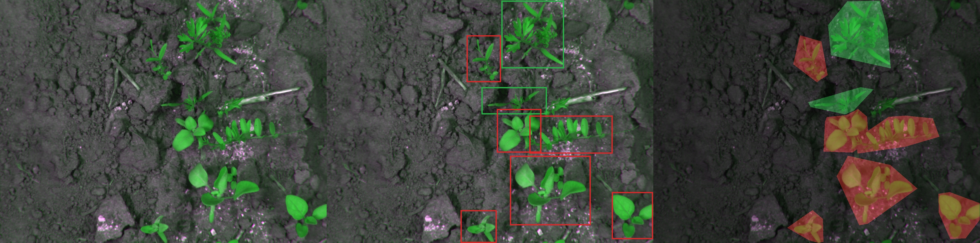

In [ ]:
from PIL import Image

# 도입 설명용 비교 이미지(잡초 Bounding Box vs Segmentation Mask) 출력
weed = ROOT / "examples" / "weed_box_vs_mask.jpg"
if weed.exists():
    show_img(Image.open(weed), width=980)
else:
    print("[안내] 도입 예시 이미지가 존재하지 않습니다:", weed)

## 5. 신경망 아키텍처 설계: U-Net 구현 및 구조 시각화

PyTorch 기본 라이브러리(`torch`, `torchvision`)에는 U-Net이 기본 내장되어 있지 않으므로, 논문(Ronneberger et al., 2015)의 핵심 구조를 실습 환경에 맞게 경량화하여 직접 구현합니다.

### 🧠 U-Net 핵심 구성 요소 및 변수 명명 규칙
U-Net은 알파벳 **'U'** 형태의 대칭형 구조를 가지며, 크게 특징을 압축하는 **인코더(수축 경로, Contracting Path)**와 해상도를 복원하는 **디코더(확장 경로, Expansive Path)**로 나뉩니다.
코드의 변수명에서 **접두사는 역할**, **숫자(1~4)는 네트워크의 깊이(해상도 단계)**를 의미합니다. (숫자 1이 원본 해상도와 가장 가깝고, 4가 가장 깊은 저해상도 계층입니다.)

- **`DoubleConv`**: `(Conv2d 3×3 → BatchNorm2d → ReLU) × 2` 블록. 해상도를 유지한 채 특징(Feature)을 추출합니다.
- **`enc1` ~ `enc4` (Encoder)**: `MaxPool2d(2)`를 거치며 가로·세로 해상도를 절반($1/2$)으로 줄이고, 채널 수를 2배씩 늘려가며 문맥(Context) 정보를 압축합니다.
- **`skip1` ~ `skip4` (Skip Connection 텐서)**: 각 인코더 단계의 출력값입니다. 풀링(Pooling)으로 손실되기 전의 **고해상도 위치(Localization) 및 경계선 정보**를 간직하고 있으며, 동일한 깊이(숫자)의 디코더로 직접 전달됩니다.
- **`bottleneck`**: U자 구조의 가장 바닥(최하단) 계층으로, 가장 작은 해상도와 가장 많은 채널(추상화된 고차원 특징)을 가집니다.
- **`up4` ~ `up1` (Upsampling)**: `ConvTranspose2d`(전치 합성곱, 커널 2, 스트라이드 2)를 사용해 가로·세로 해상도를 2배로 키우고 채널 수를 절반으로 줄입니다.
- **`merged4` ~ `merged1` (Skip Concatenation)**: 업샘플링된 특징 맵(`upN`)과 인코더에서 건너온 특징 맵(`skipN`)을 **채널 방향(`dim=1`)으로 이어 붙인(Concatenate)** 텐서입니다. (이를 통해 *'무엇인지(What)'*와 *'어디에 있는지(Where)'* 정보를 결합합니다.)
- **`dec4` ~ `dec1` (Decoder)**: 결합된 `mergedN` 텐서에 다시 `DoubleConv`를 적용하여 정교한 특징 맵을 복원합니다.
- **`head`**: 마지막 $1\times1$ 합성곱(`Conv2d`) 계층으로, 채널 수를 클래스 개수(`out_ch=1`, 이진 분할)로 줄여 픽셀별 로짓(Logit) 점수를 출력합니다.

> 💡 단순한 `print(model)` 명령어로는 `forward()` 내부에서 일어나는 **Skip Connection(`torch.cat`) 흐름**을 볼 수 없으므로, 아래 셀에서는 더미 텐서를 통과시켜 각 계층의 텐서 크기(Shape)와 연결 구조를 다이어그램으로 그리는 `show_unet_stack()` 함수를 함께 정의합니다.

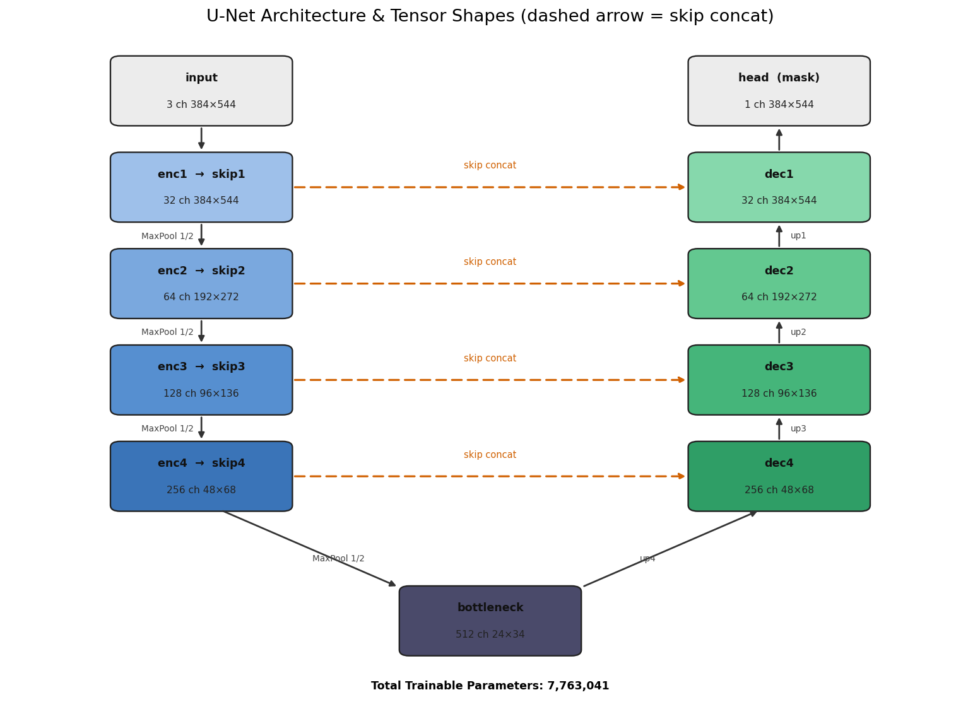

In [ ]:
import torch
from torch import nn


class DoubleConv(nn.Module):
    """
    U-Net의 기본 연산 블록: (3x3 Conv -> BatchNorm -> ReLU) 과정을 연속으로 2번 수행합니다.
    padding=1을 사용하여 입출력의 가로/세로 해상도(H, W)가 동일하게 유지됩니다.
    """

    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        # 뒤에 BatchNorm2d가 바로 따라오므로 Conv2d의 bias는 불필요하여 False로 설정
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class UNet(nn.Module):
    """
    경량화된 4단계 깊이(Depth=4)의 U-Net 아키텍처
    - in_ch : 입력 이미지 채널 수 (RGB=3)
    - out_ch: 출력 마스크 채널 수 (이진 분할=1)
    - base  : 첫 번째 인코더의 기본 채널 수 (기본값 32, 깊어질수록 64 -> 128 -> 256 -> 512로 증가)
    """

    def __init__(self, in_ch: int = 3, out_ch: int = 1, base: int = 32):
        super().__init__()

        # -----------------------------------------------------------
        # 1. Encoder (Contracting Path): 해상도 축소 및 채널 확장
        # -----------------------------------------------------------
        self.enc1 = DoubleConv(in_ch, base)          # [B, 3, H, W]     -> [B, 32, H, W]
        self.enc2 = DoubleConv(base, base * 2)       # [B, 32, H/2, W/2] -> [B, 64, H/2, W/2]
        self.enc3 = DoubleConv(base * 2, base * 4)   # [B, 64, H/4, W/4] -> [B, 128, H/4, W/4]
        self.enc4 = DoubleConv(base * 4, base * 8)   # [B, 128, H/8, W/8]-> [B, 256, H/8, W/8]

        # 다운샘플링을 위한 2x2 Max Pooling (해상도를 1/2로 축소)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # -----------------------------------------------------------
        # 2. Bottleneck: 최하단 특징 압축 계층 (해상도 1/16)
        # -----------------------------------------------------------
        self.bottleneck = DoubleConv(base * 8, base * 16)  # -> [B, 512, H/16, W/16]

        # -----------------------------------------------------------
        # 3. Decoder (Expansive Path): 해상도 복원 및 Skip Connection 결합
        # -----------------------------------------------------------
        # upN : 전치 합성곱(Transposed Conv)으로 해상도를 2배 확대, 채널은 절반으로 축소
        # decN: (upN 채널 + skipN 채널)이 합쳐지므로 입력 채널이 다시 2배이며, 이를 절반으로 압축
        self.up4 = nn.ConvTranspose2d(base * 16, base * 8, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(base * 16, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(base * 8, base * 4)

        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(base * 4, base * 2)

        self.up1 = nn.ConvTranspose2d(base * 2, base, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(base * 2, base)

        # -----------------------------------------------------------
        # 4. Prediction Head: 1x1 합성곱으로 최종 픽셀별 Logit 값 산출
        # -----------------------------------------------------------
        self.head = nn.Conv2d(base, out_ch, kernel_size=1) # [B, 32, H, W] -> [B, 1, H, W]

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # [인코더 경로] 각 단계의 출력을 skip 변수에 보관
        skip1 = self.enc1(x)
        skip2 = self.enc2(self.pool(skip1))
        skip3 = self.enc3(self.pool(skip2))
        skip4 = self.enc4(self.pool(skip3))

        # [바틀넥 경로]
        bottleneck = self.bottleneck(self.pool(skip4))

        # [디코더 경로] 업샘플링 후 대응하는 인코더의 skip 텐서와 채널 차원(dim=1)으로 결합(Concat)
        up4 = self.up4(bottleneck)
        merged4 = torch.cat([up4, skip4], dim=1)  # 채널: 256 + 256 = 512
        dec4 = self.dec4(merged4)                 # 채널: 512 -> 256

        up3 = self.up3(dec4)
        merged3 = torch.cat([up3, skip3], dim=1)  # 채널: 128 + 128 = 256
        dec3 = self.dec3(merged3)                 # 채널: 256 -> 128

        up2 = self.up2(dec3)
        merged2 = torch.cat([up2, skip2], dim=1)  # 채널: 64 + 64 = 128
        dec2 = self.dec2(merged2)                 # 채널: 128 -> 64

        up1 = self.up1(dec2)
        merged1 = torch.cat([up1, skip1], dim=1)  # 채널: 32 + 32 = 64
        dec1 = self.dec1(merged1)                 # 채널: 64 -> 32

        # 최종 픽셀별 예측 로짓 반환 (활성화 함수 Sigmoid는 손실 함수 및 추론 시 적용)
        return self.head(dec1)


def show_unet_stack(model: nn.Module, h: int = 384, w: int = 544):
    """
    가상의 더미 이미지 1장(1, 3, h, w)을 모델에 통과시킨 뒤,
    U-Net의 계층별 텐서 크기(채널, 해상도)와 Skip Connection 구조를 다이어그램으로 시각화합니다.
    """
    from io import BytesIO
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyBboxPatch
    from PIL import Image

    model.eval()
    x = torch.zeros(1, 3, h, w)
    with torch.no_grad():
        skip1 = model.enc1(x)
        skip2 = model.enc2(model.pool(skip1))
        skip3 = model.enc3(model.pool(skip2))
        skip4 = model.enc4(model.pool(skip3))
        bottleneck = model.bottleneck(model.pool(skip4))
        dec4 = model.dec4(torch.cat([model.up4(bottleneck), skip4], dim=1))
        dec3 = model.dec3(torch.cat([model.up3(dec4), skip3], dim=1))
        dec2 = model.dec2(torch.cat([model.up2(dec3), skip2], dim=1))
        dec1 = model.dec1(torch.cat([model.up1(dec2), skip1], dim=1))
        out = model.head(dec1)

    def label(t):
        _, c, hh, ww = t.shape
        return f"{c} ch {hh}×{ww}"

    fig, ax = plt.subplots(figsize=(11.2, 8.2))
    ax.set_xlim(0, 10)
    ax.set_ylim(0.15, 11.35)
    ax.axis("off")
    ax.set_title("U-Net Architecture & Tensor Shapes (dashed arrow = skip concat)", fontsize=14, pad=8)

    boxes = {}

    def box(key, cx, cy, title, tensor, color):
        bw, bh = 1.85, 1.12
        patch = FancyBboxPatch(
            (cx - bw / 2, cy - bh / 2),
            bw,
            bh,
            boxstyle="round,pad=0.02,rounding_size=0.1",
            facecolor=color,
            edgecolor="#222",
            linewidth=1.2,
        )
        ax.add_patch(patch)
        ax.text(cx, cy + 0.22, title, ha="center", va="center", fontsize=9, fontweight="bold", color="#111")
        ax.text(cx, cy - 0.22, label(tensor), ha="center", va="center", fontsize=8, color="#222")
        boxes[key] = (cx, cy, bw, bh)

    def down(src, dst, text):
        x1, y1, _, h1 = boxes[src]
        x2, y2, _, h2 = boxes[dst]
        ax.annotate(
            "",
            xy=(x2, y2 + h2 / 2 + 0.02),
            xytext=(x1, y1 - h1 / 2 - 0.02),
            arrowprops=dict(arrowstyle="-|>", color="#333", lw=1.4, mutation_scale=10),
        )
        ax.text((x1 + x2) / 2 - 0.08, (y1 + y2) / 2, text, fontsize=7, color="#444", ha="right", va="center")

    def skip(src, dst):
        x1, y1, w1, _ = boxes[src]
        x2, y2, w2, _ = boxes[dst]
        ax.annotate(
            "",
            xy=(x2 - w2 / 2 - 0.02, y2),
            xytext=(x1 + w1 / 2 + 0.02, y1),
            arrowprops=dict(
                arrowstyle="-|>",
                color="#d06000",
                lw=1.6,
                ls=(0, (5, 3)),
                mutation_scale=10,
            ),
        )
        ax.text((x1 + x2) / 2, y1 + 0.32, "skip concat", ha="center", fontsize=7.5, color="#d06000")

    box("in", 2.0, 10.35, "input", x, "#ececec")
    box("e1", 2.0, 8.75, "enc1  →  skip1", skip1, "#9ec0ea")
    box("e2", 2.0, 7.15, "enc2  →  skip2", skip2, "#7aa8de")
    box("e3", 2.0, 5.55, "enc3  →  skip3", skip3, "#568fd0")
    box("e4", 2.0, 3.95, "enc4  →  skip4", skip4, "#3a74b8")
    box("bot", 5.0, 1.55, "bottleneck", bottleneck, "#4a4a6a")
    box("d4", 8.0, 3.95, "dec4", dec4, "#2f9e66")
    box("d3", 8.0, 5.55, "dec3", dec3, "#45b57a")
    box("d2", 8.0, 7.15, "dec2", dec2, "#63c890")
    box("d1", 8.0, 8.75, "dec1", dec1, "#86d8ac")
    box("head", 8.0, 10.35, "head  (mask)", out, "#ececec")

    down("in", "e1", "")
    down("e1", "e2", "MaxPool 1/2")
    down("e2", "e3", "MaxPool 1/2")
    down("e3", "e4", "MaxPool 1/2")

    x1, y1, _, h1 = boxes["e4"]
    x2, y2, _, h2 = boxes["bot"]
    ax.annotate(
        "",
        xy=(x2 - 0.95, y2 + h2 / 2),
        xytext=(x1 + 0.2, y1 - h1 / 2),
        arrowprops=dict(arrowstyle="-|>", color="#333", lw=1.4, mutation_scale=10),
    )
    ax.text(3.15, 2.55, "MaxPool 1/2", fontsize=7, color="#444")
    x3, y3, _, h3 = boxes["d4"]
    ax.annotate(
        "",
        xy=(x3 - 0.2, y3 - h3 / 2),
        xytext=(x2 + 0.95, y2 + h2 / 2),
        arrowprops=dict(arrowstyle="-|>", color="#333", lw=1.4, mutation_scale=10),
    )
    ax.text(6.55, 2.55, "up4", fontsize=7, color="#444")

    for src, dst, text in (("d4", "d3", "up3"), ("d3", "d2", "up2"), ("d2", "d1", "up1"), ("d1", "head", "")):
        x1, y1, _, h1 = boxes[src]
        x2, y2, _, h2 = boxes[dst]
        ax.annotate(
            "",
            xy=(x2, y2 - h2 / 2 - 0.02),
            xytext=(x1, y1 + h1 / 2 + 0.02),
            arrowprops=dict(arrowstyle="-|>", color="#333", lw=1.4, mutation_scale=10),
        )
        if text:
            ax.text(x1 + 0.12, (y1 + y2) / 2, text, fontsize=7, color="#444", ha="left", va="center")

    skip("e1", "d1")
    skip("e2", "d2")
    skip("e3", "d3")
    skip("e4", "d4")

    n = sum(p.numel() for p in model.parameters())
    ax.text(5.0, 0.42, f"Total Trainable Parameters: {n:,}", ha="center", fontsize=9, fontweight="bold")

    fig.tight_layout()
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=140, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    buf.seek(0)
    show_img(Image.open(buf), width=980)


# U-Net 인스턴스 생성 및 아키텍처 다이어그램 출력
show_unet_stack(UNet())

## 6. 데이터셋 로더, 손실 함수(BCE + Dice) 및 모델 학습

### 📊 왜 BCE(Binary Cross-Entropy) 단독으로 쓰지 않고 Dice Loss를 더할까?
- 노면 균열 이미지에서는 전체 픽셀의 **98% 이상이 배경(0)**이고, **균열(1)은 1~2%**에 불과합니다 (심각한 클래스 불균형, Class Imbalance).
- 만약 픽셀 단위로만 오차를 계산하는 **BCE Loss**만 사용하면, 모델이 모든 픽셀을 무조건 '배경(0)'이라고 찍어도 98% 이상의 정확도가 나오기 때문에 가느다란 균열을 제대로 학습하지 못하고 배경에 묻혀버립니다.
- **Dice Loss**는 예측 마스크($P$)와 정답 마스크($G$)가 **얼마나 겹치는지(교집합 비율)**를 직접 최적화합니다:
  $$\text{Dice Coefficient} = \frac{2 \sum (P \cdot G) + \epsilon}{\sum P + \sum G + \epsilon}, \quad \text{Dice Loss} = 1 - \text{Dice Coefficient}$$
- 따라서 픽셀 단위 수렴을 돕는 **BCE**와 영역 중첩도를 높이는 **Dice Loss**를 결합(`BCE + Dice`)하면 가느다란 균열도 놓치지 않고 선명하게 잡아낼 수 있습니다.

### 📏 세그멘테이션 핵심 평가지표: IoU와 Dice Score
- **IoU (Intersection over Union, Jaccard Index)**: 예측 영역과 정답 영역의 **합집합 대비 교집합의 비율**입니다. ($\frac{|P \cap G|}{|P \cup G|}$)
- **Dice Score (F1-Score와 동일 개념)**: 예측 영역과 정답 영역의 **크기 합 대비 교집합의 2배 비율**입니다. ($\frac{2|P \cap G|}{|P| + |G|}$)

> ⚠️ **전처리 주의사항**: 입력 원본 이미지(`RGB`)를 리사이즈할 때는 자연스러운 색상 보간을 위해 `Image.BILINEAR`를 사용하지만, 정답 마스크(`mask`)를 리사이즈할 때는 경계선에 애매한 중간 회색값(0.3, 0.7 등)이 생기지 않도록 반드시 **`Image.NEAREST`(최근접 이웃 보간법)**를 사용해야 합니다.

In [ ]:
import json
import random

import torch
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms.functional import to_tensor

# -----------------------------------------------------------
# 하이퍼파라미터(Hyperparameters) 설정
# -----------------------------------------------------------
EPOCHS = 25              # 전체 데이터셋 반복 학습 횟수
BATCH = 12               # 미니배치(Mini-batch) 크기
WIDTH, HEIGHT = 544, 384 # 입력 해상도 (U-Net에서 1/16로 풀링되므로 16의 배수로 설정)
LR = 1e-3                # 학습률 (Learning Rate)
SEED = 42                # 재현성을 위한 랜덤 시드


class CrackDataset(Dataset):
    """
    노면 균열 이미지(.jpg)와 정답 마스크(.png) 쌍을 불러오는 커스텀 PyTorch Dataset 클래스
    """

    def __init__(self, img_dir, lab_dir, size):
        self.images = sorted(img_dir.glob("*.jpg"))
        if not self.images:
            raise FileNotFoundError(f"[오류] 이미지 파일이 없습니다: {img_dir}")
        self.lab_dir = lab_dir
        self.size = size  # (WIDTH, HEIGHT) 튜플 (PIL.Image.resize 규격)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_p = self.images[idx]
        # 이미지 파일명(stem)과 동일한 이름의 .png 마스크 파일 매칭
        lab_p = self.lab_dir / f"{img_p.stem}.png"

        # 1. 입력 이미지 로드 및 리사이징 (연속적인 픽셀이므로 BILINEAR 보간 사용)
        img = Image.open(img_p).convert("RGB").resize(self.size, Image.BILINEAR)

        # 2. 정답 마스크 로드(흑백 'L' 모드) 및 리사이징 (클래스 레이블 보존을 위해 NEAREST 보간 사용)
        mask = Image.open(lab_p).convert("L").resize(self.size, Image.NEAREST)

        # 3. PIL Image -> PyTorch Tensor 변환 ([0.0, 1.0] 범위로 정규화 및 [C, H, W] 차원 정렬)
        x = to_tensor(img)
        # 마스크 픽셀값이 0.5보다 크면 1.0(균열), 아니면 0.0(배경)인 이진(Binary) Float 텐서로 변환
        y = (to_tensor(mask) > 0.5).float()
        return x, y, img_p.name


def set_seed(seed: int):
    """실험 결과 재현(Reproducibility)을 위해 난수 시드를 고정합니다."""
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def bce_dice(logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
    """
    BCE(Binary Cross-Entropy) 손실과 Soft Dice 손실을 합산한 복합 손실 함수

    Args:
        logits: 모델의 마지막 계층 출력값 (Sigmoid 통과 전, shape: [B, 1, H, W])
        target: 정답 이진 마스크 (0.0 또는 1.0, shape: [B, 1, H, W])
    """
    # 1. 픽셀 단위 이진 교차 엔트로피 손실 (내부적으로 Sigmoid를 포함하여 수치적으로 안정적임)
    bce = F.binary_cross_entropy_with_logits(logits, target)

    # 2. 영역 기반 Soft Dice 손실 계산
    p = logits.sigmoid()  # 로짓을 [0, 1] 범위의 확률값으로 변환
    # 배치(0)와 공간 차원(2, 3)에 대해 합산하여 교집합(num)과 합(den) 계산
    num = 2 * (p * target).sum(dim=(0, 2, 3))
    den = p.sum(dim=(0, 2, 3)) + target.sum(dim=(0, 2, 3))
    # 분모가 0이 되는 현상(Zero-division)을 막기 위해 스무딩 상수(1.0) 추가
    dice = 1.0 - (num + 1.0) / (den + 1.0)

    return bce + dice.mean()


@torch.no_grad()
def eval_metrics(model: torch.nn.Module, loader: DataLoader) -> dict:
    """
    검증(Validation) 데이터셋 전체에 대해 IoU와 Dice Score를 평가하는 함수
    """
    model.eval()  # 평가 모드 전환 (BatchNorm 통계량 고정 등)
    inter = union = dice_num = dice_den = 0.0

    for x, y, _ in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        # 예측 확률이 0.5를 초과하면 균열(1.0)로 이진화
        pred = (model(x).sigmoid() > 0.5).float()

        # 교집합(Intersection) 및 합집합(Union) 픽셀 수 누적
        inter += (pred * y).sum().item()
        union += ((pred + y) > 0).float().sum().item()

        # Dice 분자(2 * 교집합) 및 분모(예측 픽셀 수 + 정답 픽셀 수) 누적
        dice_num += 2 * (pred * y).sum().item()
        dice_den += pred.sum().item() + y.sum().item()

    return {
        "iou": inter / max(union, 1.0),
        "dice": dice_num / max(dice_den, 1.0),
    }


# -----------------------------------------------------------
# 데이터셋 및 데이터로더 초기화
# -----------------------------------------------------------
set_seed(SEED)
size = (WIDTH, HEIGHT)
data = ROOT / "dataset"
runs = ROOT / "runs"  # 학습된 가중치(best.pt)를 저장할 폴더

train_ds = CrackDataset(data / "train_img", data / "train_lab", size)
val_ds = CrackDataset(data / "test_img", data / "test_lab", size)

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=0)

print(f"📊 학습 데이터: {len(train_ds)}장 | 검증 데이터: {len(val_ds)}장 | 입력 크기: {WIDTH}x{HEIGHT}")

# -----------------------------------------------------------
# 모델, 옵티마이저 초기화 및 학습 루프(Training Loop) 실행
# -----------------------------------------------------------
model = UNet().to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
runs.mkdir(parents=True, exist_ok=True)
best_dice = -1.0

for epoch in range(1, EPOCHS + 1):
    model.train()  # 학습 모드 전환
    running = 0.0
    n = 0

    for x, y, _ in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)

        # 1. 기울기(Gradient) 초기화 (set_to_none=True로 메모리 연산 최적화)
        optimizer.zero_grad(set_to_none=True)
        # 2. 순전파(Forward) 및 손실(BCE + Dice) 계산
        loss = bce_dice(model(x), y)
        # 3. 역전파(Backward)로 기울기 계산
        loss.backward()
        # 4. 가중치 업데이트
        optimizer.step()

        running += loss.item() * x.size(0)
        n += x.size(0)

    # 매 에포크 종료 후 검증 세트로 성능(Dice, IoU) 측정
    metrics = eval_metrics(model, val_loader)
    print(
        f"epoch {epoch:03d}/{EPOCHS:03d} | train loss: {running / n:.4f} | "
        f"val dice: {metrics['dice']:.3f} | val iou: {metrics['iou']:.3f}"
    )

    # 최고 검증 Dice 점수를 갱신할 때마다 모델 가중치 체크포인트 저장
    if metrics["dice"] >= best_dice:
        best_dice = metrics["dice"]
        torch.save({"model": model.state_dict(), "size": size}, runs / "best.pt")

print("\n✅ 학습 완료! 최고 성능 모델 저장 경로:", runs / "best.pt", "| 최고 Val Dice:", round(best_dice, 4))

📊 학습 데이터: 300장 | 검증 데이터: 237장 | 입력 크기: 544x384
epoch 001/025 | train loss: 1.3692 | val dice: 0.140 | val iou: 0.075
epoch 002/025 | train loss: 1.1778 | val dice: 0.733 | val iou: 0.578
epoch 003/025 | train loss: 1.0714 | val dice: 0.741 | val iou: 0.588
epoch 004/025 | train loss: 0.9679 | val dice: 0.742 | val iou: 0.590
epoch 005/025 | train loss: 0.8733 | val dice: 0.604 | val iou: 0.433
epoch 006/025 | train loss: 0.7727 | val dice: 0.732 | val iou: 0.577
epoch 007/025 | train loss: 0.6710 | val dice: 0.740 | val iou: 0.587
epoch 008/025 | train loss: 0.5846 | val dice: 0.778 | val iou: 0.636
epoch 009/025 | train loss: 0.4834 | val dice: 0.772 | val iou: 0.628
epoch 010/025 | train loss: 0.4508 | val dice: 0.737 | val iou: 0.583
epoch 011/025 | train loss: 0.4028 | val dice: 0.749 | val iou: 0.599
epoch 012/025 | train loss: 0.3907 | val dice: 0.749 | val iou: 0.599
epoch 013/025 | train loss: 0.3434 | val dice: 0.811 | val iou: 0.682
epoch 014/025 | train loss: 0.3211 | val di

## 7. 학습된 모델 추론(Inference) 및 결과 비교 시각화

저장된 최고 성능 가중치(`best.pt`)를 불러와 예시 이미지들에 대해 균열 영역을 추론합니다.

### 🖼️ 4단 비교 패널 구성 (왼쪽부터 순서대로)
1. **`input`**: 모델에 입력된 원본 노면 이미지
2. **`GT mask`**: 사람이 직접 레이블링한 정답 균열 마스크 (파란색 오버레이)
3. **`U-Net pred`**: 학습된 U-Net이 픽셀 단위로 예측한 균열 마스크 (초록색 오버레이)
4. **`pred as one box`**: U-Net이 찾은 균열 픽셀들의 최소/최대 좌표를 감싸 **하나의 Bounding Box(빨간색 직사각형)**로 근사한 결과

### 🔍 정량적 비교 포인트
- 각 이미지 출력 상단에 **실제 예측된 균열 픽셀 수**, **Bounding Box 전체 픽셀 수(및 박스 내부의 배경 비율 %)**, 그리고 정답과의 일치도인 **Dice 점수**를 함께 출력합니다.
- 결과를 통해 **"균열을 박스로 감싸면 박스 내부의 95~98% 이상이 불필요한 배경(정상 도로)이 된다"**는 사실을 실제 추론 데이터로 명확히 확인할 수 있습니다.

📌 파일명: 01.jpg
  - 예측된 균열 픽셀 수 : 2,478 px
  - 외접 박스 전체 면적 : 140,418 px (박스 내부 중 정상 노면/배경 비율: 98.2%)
  - 정답 대비 Dice 점수 : 0.740


/tmp/ipykernel_1330/25067042.py:35: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  m = Image.fromarray((mask * 255).astype(np.uint8), mode="L")


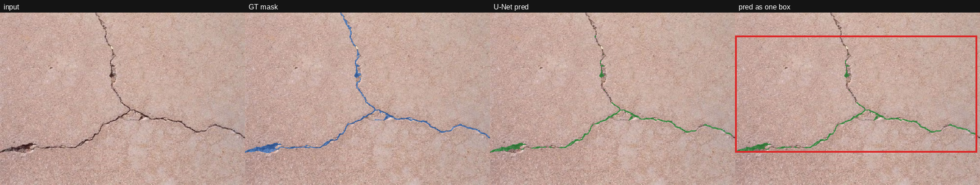


📌 파일명: 02.jpg
  - 예측된 균열 픽셀 수 : 4,774 px
  - 외접 박스 전체 면적 : 142,868 px (박스 내부 중 정상 노면/배경 비율: 96.7%)
  - 정답 대비 Dice 점수 : 0.585


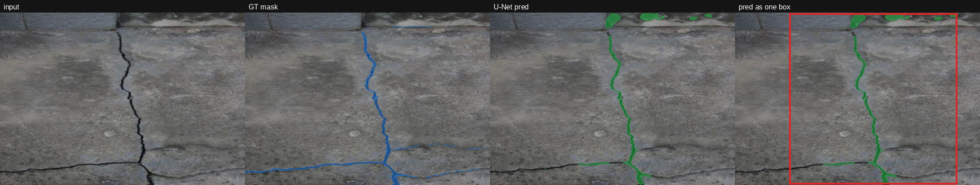


📌 파일명: 03.jpg
  - 예측된 균열 픽셀 수 : 3,775 px
  - 외접 박스 전체 면적 : 167,650 px (박스 내부 중 정상 노면/배경 비율: 97.7%)
  - 정답 대비 Dice 점수 : 0.747


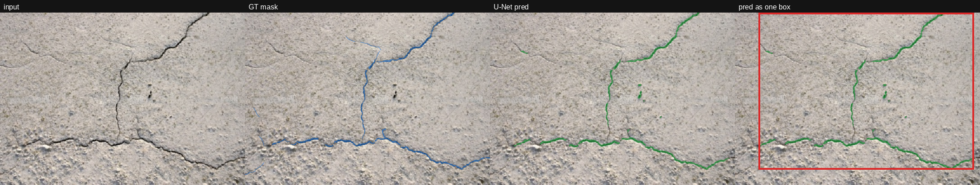

In [ ]:
import numpy as np
import torch
from PIL import Image, ImageDraw, ImageFont


def font(size: int):
    """리눅스(Colab) 환경에 설치된 기본 트루타입 폰트를 불러옵니다."""
    for path in (
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf",
    ):
        try:
            return ImageFont.truetype(path, size)
        except OSError:
            continue
    return ImageFont.load_default()


def mask_aabb(mask: np.ndarray):
    """
    이진 마스크에서 값이 1(True)인 픽셀들을 모두 감싸는
    최소 외접 직사각형(AABB: Axis-Aligned Bounding Box) 좌표 (x_min, y_min, x_max, y_max)를 구합니다.
    """
    ys, xs = np.where(mask > 0)
    if xs.size == 0:
        return None
    return int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())


def blend(img: Image.Image, mask: np.ndarray, color: tuple, alpha: float) -> Image.Image:
    """
    원본 이미지(img) 위에 마스크(mask) 영역만 지정한 색상(color)과 투명도(alpha)로 반투명하게 합성합니다.
    """
    overlay = Image.new("RGB", img.size, color)
    m = Image.fromarray((mask * 255).astype(np.uint8), mode="L")
    return Image.composite(Image.blend(img, overlay, alpha), img, m)


def caption(img: Image.Image, text: str) -> Image.Image:
    """이미지 상단에 검은색 제목 표시줄(Caption Bar)을 덧붙여 반환합니다."""
    bar_h = 28
    canvas = Image.new("RGB", (img.width, img.height + bar_h), (20, 20, 20))
    canvas.paste(img, (0, bar_h))
    draw = ImageDraw.Draw(canvas)
    draw.text((8, 6), text, fill=(255, 255, 255), font=font(16))
    return canvas


# -----------------------------------------------------------
# 1. 저장된 최고 성능 모델 가중치(best.pt) 로드
# -----------------------------------------------------------
weights = ROOT / "runs" / "best.pt"
ckpt = torch.load(weights, map_location="cpu", weights_only=True)
size = tuple(ckpt.get("size", (544, 384)))

model = UNet()
model.load_state_dict(ckpt["model"])
model.eval()

# 추론할 샘플 이미지 목록 정렬 (01.jpg, 02.jpg, ...)
images = sorted((ROOT / "examples").glob("[0-9][0-9].jpg"))

# -----------------------------------------------------------
# 2. 샘플별 추론 및 4단 비교 시각화 수행
# -----------------------------------------------------------
for path in images:
    # 원본 이미지 로드 및 모델 입력 해상도로 리사이징
    raw = Image.open(path).convert("RGB")
    img = raw.resize(size, Image.BILINEAR)

    # [H, W, C] numpy 배열 -> [C, H, W] PyTorch 텐서 변환 및 [0, 1] 정규화
    x = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255.0

    # 배치 차원(unsqueeze(0)) 추가 후 모델 추론 -> Sigmoid 확률 0.5 기준 이진 마스크 생성
    with torch.no_grad():
        pred = (model(x.unsqueeze(0)).sigmoid()[0, 0] > 0.5).cpu().numpy()

    # (패널 3) U-Net 예측 마스크를 초록색(40, 200, 80)으로 반투명 오버레이
    pred_ov = blend(img, pred, (40, 200, 80), 0.5)

    # (패널 4) 예측된 마스크를 감싸는 단일 외접 직사각형(Bounding Box) 그리기
    boxed = pred_ov.copy()
    box = mask_aabb(pred)
    if box:
        ImageDraw.Draw(boxed).rectangle(box, outline=(220, 40, 40), width=4)

    # (패널 2) 정답 마스크(GT)가 존재하면 파란색(40, 140, 255)으로 오버레이
    mask_path = path.parent / f"{path.stem}_mask.png"
    gt = None
    if mask_path.exists():
        gt = np.array(Image.open(mask_path).convert("L").resize(size, Image.NEAREST)) > 127
        gt_panel = blend(img, gt, (40, 140, 255), 0.5)
    else:
        gt_panel = img.copy()

    # 4개의 패널을 가로로 나란히 이어 붙이기
    panels = [
        caption(img, "input"),
        caption(gt_panel, "GT mask" if gt is not None else "GT missing"),
        caption(pred_ov, "U-Net pred"),
        caption(boxed, "pred as one box"),
    ]
    w, h = panels[0].size
    canvas = Image.new("RGB", (w * 4, h))
    for i, panel in enumerate(panels):
        canvas.paste(panel, (i * w, 0))

    # 정량 수치(균열 픽셀 수, 박스 면적 대비 배경 비율, Dice Score) 계산 및 출력
    crack_px = int(pred.sum())
    box_px = 0 if box is None else (box[2] - box[0] + 1) * (box[3] - box[1] + 1)

    print(f"📌 파일명: {path.name}")
    print(f"  - 예측된 균열 픽셀 수 : {crack_px:,} px")
    if box_px:
        bg_ratio = 1.0 - (crack_px / box_px)
        print(f"  - 외접 박스 전체 면적 : {box_px:,} px (박스 내부 중 정상 노면/배경 비율: {bg_ratio:.1%})")
    if gt is not None:
        inter = float((pred & gt).sum())
        den = float(pred.sum() + gt.sum())
        dice = (2 * inter / den) if den else 0.0
        print(f"  - 정답 대비 Dice 점수 : {dice:.3f}")

    show_img(canvas, width=980)
    print()